<a href="https://colab.research.google.com/github/naylaakas/PembelajaranMesin-2026/blob/main/JS06/datasetPBL/Praktikum3-HNSW.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
!pip install hnswlib

  Installing build dependencies ... done
  Getting requirements to build wheel ... done
  Preparing metadata (pyproject.toml) ... done
  Created wheel for hnswlib: filename=hnswlib-0.8.0-cp313-cp313-linux_x86_64.whl size=2679800 sha256=bcffc8e9e0f2415c36a4d9b28aae1c377fb9946909bcd4424aca29845a0be2b0
  Stored in directory: /root/.cache/pip/wheels/35/04/88/b31765a4b9957705e18065db4657e61fc8da54f50e3ef0b67e
Successfully built hnswlib


In [2]:
import time
import hnswlib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.neighbors import NearestNeighbors
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA

# Load dan gabungkan kedua dataset milikmu
df_cafes = pd.read_csv('cafes.csv')
df_reviews = pd.read_csv('reviews.csv')
df = pd.merge(df_reviews, df_cafes, on='cafe_id', how='left', suffixes=('_review', '_cafe'))

# Siapkan fitur 2D dan 5D bertipe float32
X_2d_full = StandardScaler().fit_transform(
    df[['latitude', 'longitude']].fillna(0).values
).astype(np.float32)

X_5d_full = StandardScaler().fit_transform(
    df[['rating_review', 'rating_cafe', 'review_count', 'latitude', 'longitude']].fillna(0).values
).astype(np.float32)

print("Shape 2D Full:", X_2d_full.shape, "| dtype:", X_2d_full.dtype)
print("Shape 5D Full:", X_5d_full.shape, "| dtype:", X_5d_full.dtype)

Shape 2D Full: (2230, 2) | dtype: float32
Shape 5D Full: (2230, 5) | dtype: float32


=== Exact NN ===
Indices  : [[265 264 263 267 266]]
Distances: [[0. 0. 0. 0. 0.]]
Waktu    : 133.7376 ms

=== HNSW ===
Indices  : [[263 266 268 269 271]]
Distances: [[0. 0. 0. 0. 0.]]
Waktu    : 0.2155 ms


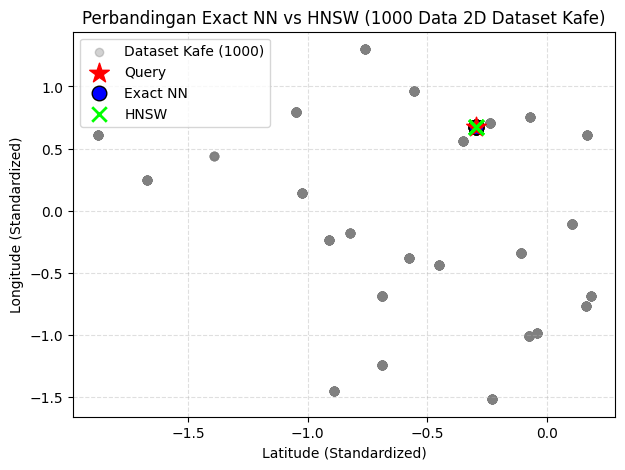

In [3]:
# 1. Ambil 1.000 data 2D pertama dari dataset kafe
data = X_2d_full[:1000].copy()
num_elements, dim = data.shape

# Query point (ambil salah satu titik dari dataset)
query = data[500:501].copy()
k = 5  # cari 5 tetangga terdekat

# ===========================
# 2. Exact NN (Brute Force)
# ===========================
nn = NearestNeighbors(n_neighbors=k, algorithm='brute', metric='euclidean')
nn.fit(data)

start = time.time()
distances_exact, indices_exact = nn.kneighbors(query)
time_exact = (time.time() - start) * 1000  # dalam ms

print("=== Exact NN ===")
print("Indices  :", indices_exact)
print("Distances:", np.round(distances_exact, 6))
print(f"Waktu    : {time_exact:.4f} ms")

# ===========================
# 3. HNSW
# ===========================
p = hnswlib.Index(space='l2', dim=dim)
p.init_index(max_elements=num_elements, ef_construction=100, M=16)
p.add_items(data)
p.set_ef(50)

start = time.time()
labels_hnsw, distances_hnsw = p.knn_query(query, k=k)
time_hnsw = (time.time() - start) * 1000  # dalam ms

print("\n=== HNSW ===")
print("Indices  :", labels_hnsw)
print("Distances:", np.round(distances_hnsw, 6))
print(f"Waktu    : {time_hnsw:.4f} ms")

# ===========================
# 4. Visualisasi Scatter Plot
# ===========================
plt.figure(figsize=(7, 5))
plt.scatter(data[:, 0], data[:, 1], alpha=0.35, color='gray', label='Dataset Kafe (1000)')
plt.scatter(query[:, 0], query[:, 1], c='red', marker='*', s=220, zorder=5, label='Query')
plt.scatter(data[indices_exact[0], 0], data[indices_exact[0], 1], c='blue', s=110, edgecolor='k', zorder=4, label='Exact NN')
plt.scatter(data[labels_hnsw[0], 0], data[labels_hnsw[0], 1], c='lime', marker='x', s=110, linewidths=2, zorder=6, label='HNSW')

plt.legend()
plt.title("Perbandingan Exact NN vs HNSW (1000 Data 2D Dataset Kafe)")
plt.xlabel("Latitude (Standardized)")
plt.ylabel("Longitude (Standardized)")
plt.grid(True, linestyle='--', alpha=0.4)
plt.show()

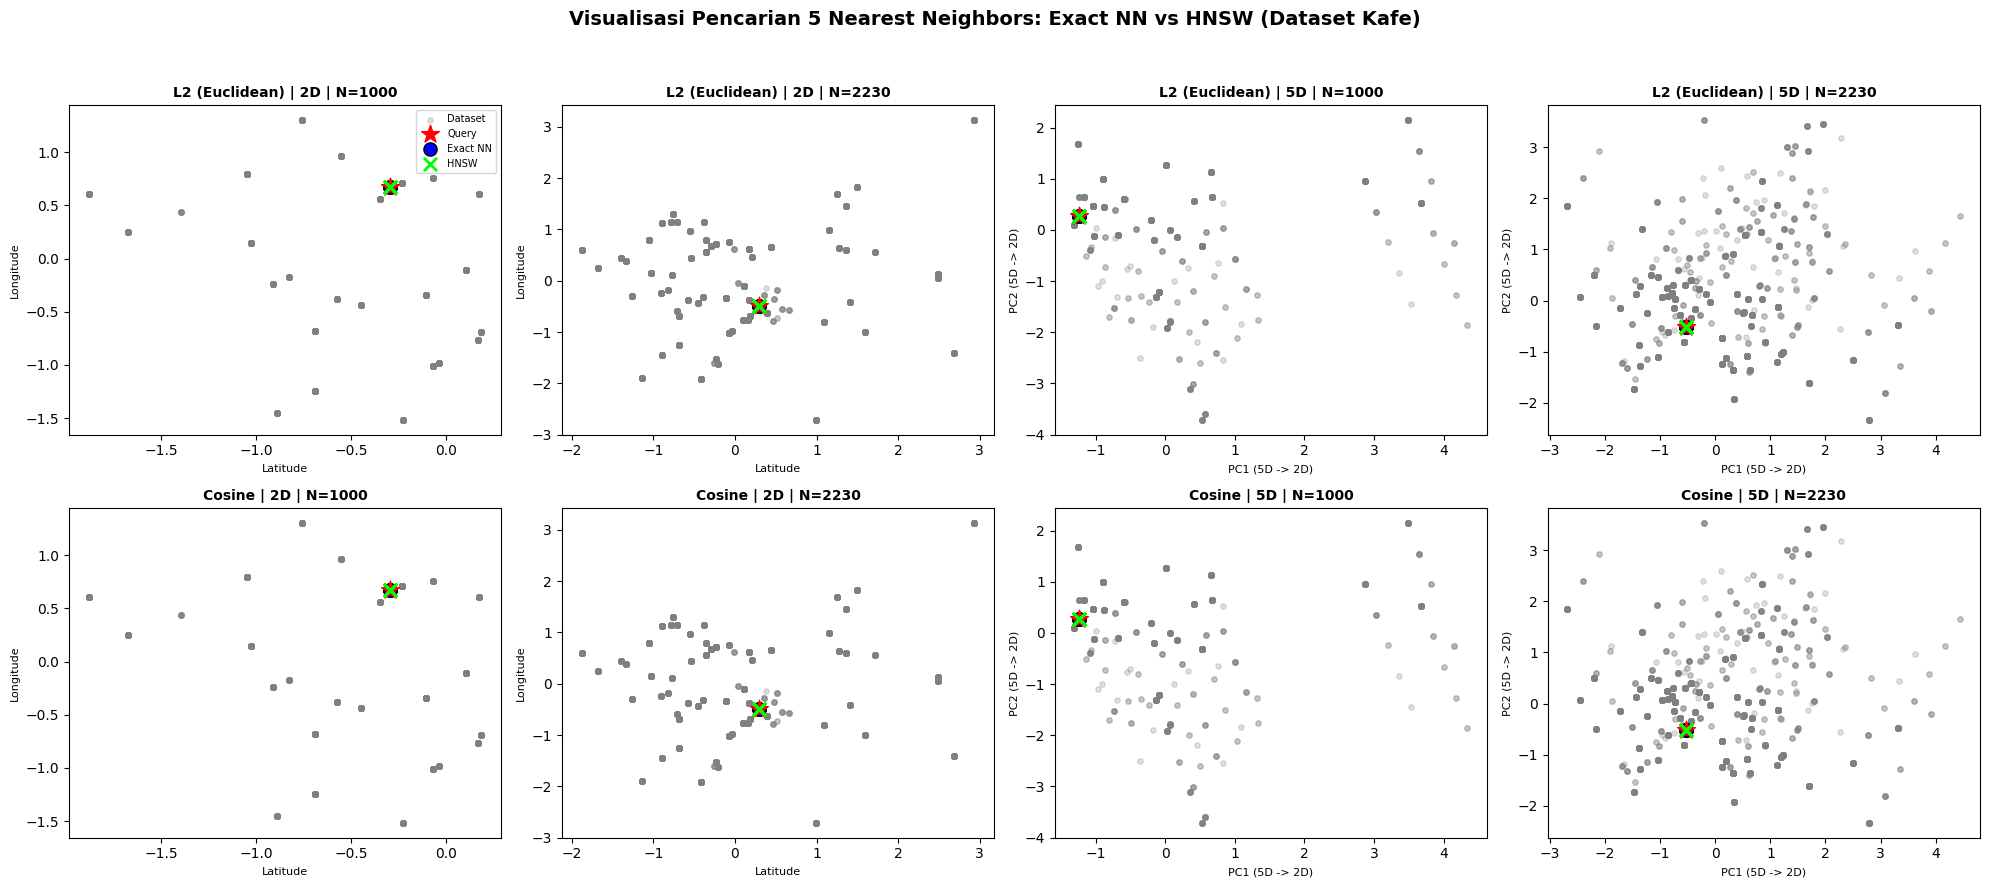

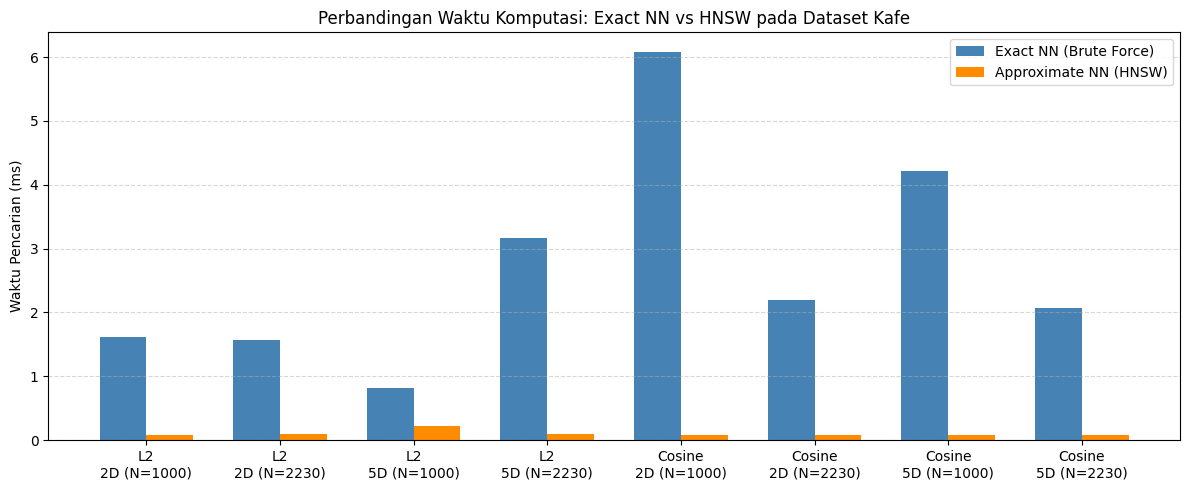


=== TABEL HASIL PERCOBAAN HNSW ===
Distance Metric Dimensi  Jumlah Data             Index Exact NN                 Index HNSW  Waktu Exact (ms)  Waktu HNSW (ms)
 L2 (Euclidean)      2D         1000      [265 264 263 267 266]      [263 267 268 269 270]            1.6077           0.0849
 L2 (Euclidean)      2D         2230 [1114 1113 1112 1116 1115] [1124 1126 1128 1133 1134]            1.5745           0.0901
 L2 (Euclidean)      5D         1000      [266 265 264 269 267]      [280 281 282 288 476]            0.8106           0.2241
 L2 (Euclidean)      5D         2230 [1114 1113 1112 1116 1115] [1113 1115 1116 1125 1130]            3.1660           0.0970
         Cosine      2D         1000      [493 492 491 490 497]      [263 264 266 268 269]            6.0847           0.0744
         Cosine      2D         2230 [1135 1136 1130 1131 1132] [1116 1117 1133 1139 1141]            2.1994           0.0842
         Cosine      5D         1000      [484 490 488 489 483]      [265 274 278 

In [4]:
daftar_eksperimen = [
    (X_2d_full[:1000], 'L2 (Euclidean)', 'l2',     'euclidean', '2D', 1000),
    (X_2d_full,        'L2 (Euclidean)', 'l2',     'euclidean', '2D', len(X_2d_full)),
    (X_5d_full[:1000], 'L2 (Euclidean)', 'l2',     'euclidean', '5D', 1000),
    (X_5d_full,        'L2 (Euclidean)', 'l2',     'euclidean', '5D', len(X_5d_full)),
    (X_2d_full[:1000], 'Cosine',         'cosine', 'cosine',    '2D', 1000),
    (X_2d_full,        'Cosine',         'cosine', 'cosine',    '2D', len(X_2d_full)),
    (X_5d_full[:1000], 'Cosine',         'cosine', 'cosine',    '5D', 1000),
    (X_5d_full,        'Cosine',         'cosine', 'cosine',    '5D', len(X_5d_full)),
]

fig, axes = plt.subplots(2, 4, figsize=(20, 9))
axes = axes.flatten()
hasil_tabel = []

for idx_plot, (X_raw, metric_label, hnsw_space, nn_metric, dim_label, n_samples) in enumerate(daftar_eksperimen):
    ax = axes[idx_plot]
    data_work = X_raw.copy()
    d = data_work.shape[1]
    q = data_work[n_samples // 2 : n_samples // 2 + 1].copy()
    k = 5

    # 1. Exact NN (Brute Force)
    nn = NearestNeighbors(n_neighbors=k, algorithm='brute', metric=nn_metric)
    nn.fit(data_work)
    t0 = time.time()
    _, idx_exact = nn.kneighbors(q)
    t_exact = (time.time() - t0) * 1000  # ms

    # 2. HNSW
    p = hnswlib.Index(space=hnsw_space, dim=d)
    p.init_index(max_elements=n_samples, ef_construction=100, M=16)
    p.add_items(data_work)
    p.set_ef(50)

    t0 = time.time()
    idx_hnsw, _ = p.knn_query(q, k=k)
    t_hnsw = (time.time() - t0) * 1000   # ms

    # Proyeksi PCA 2D khusus untuk plot data 5D
    if d > 2:
        pca = PCA(n_components=2, random_state=42)
        X_plot = pca.fit_transform(data_work)
        q_plot = pca.transform(q)
        xlabel, ylabel = "PC1 (5D -> 2D)", "PC2 (5D -> 2D)"
    else:
        X_plot = data_work
        q_plot = q
        xlabel, ylabel = "Latitude", "Longitude"

    ax.scatter(X_plot[:, 0], X_plot[:, 1], alpha=0.25, s=15, color='gray', label="Dataset")
    ax.scatter(q_plot[:, 0], q_plot[:, 1], c='red', marker='*', s=180, zorder=5, label="Query")
    ax.scatter(X_plot[idx_exact[0], 0], X_plot[idx_exact[0], 1], c='blue', s=90, edgecolor='k', zorder=4, label="Exact NN")
    ax.scatter(X_plot[idx_hnsw[0], 0], X_plot[idx_hnsw[0], 1], c='lime', marker='x', s=90, linewidths=2, zorder=6, label="HNSW")

    ax.set_title(f"{metric_label} | {dim_label} | N={n_samples}", fontsize=10, fontweight='bold')
    ax.set_xlabel(xlabel, fontsize=8)
    ax.set_ylabel(ylabel, fontsize=8)
    if idx_plot == 0:
        ax.legend(fontsize=7, loc='upper right')

    hasil_tabel.append({
        'Label': f"{metric_label.split()[0]}\n{dim_label} (N={n_samples})",
        'Distance Metric': metric_label,
        'Dimensi': dim_label,
        'Jumlah Data': n_samples,
        'Index Exact NN': str(idx_exact[0]),
        'Index HNSW': str(idx_hnsw[0]),
        'Waktu Exact (ms)': round(t_exact, 4),
        'Waktu HNSW (ms)': round(t_hnsw, 4)
    })

plt.suptitle("Visualisasi Pencarian 5 Nearest Neighbors: Exact NN vs HNSW (Dataset Kafe)", fontsize=14, fontweight='bold')
plt.tight_layout(rect=[0, 0, 1, 0.95])
plt.show()

# Plot Grafik Batang Perbandingan Waktu Komputasi
df_res = pd.DataFrame(hasil_tabel)
x_pos = np.arange(len(df_res))
width = 0.35

plt.figure(figsize=(12, 5))
plt.bar(x_pos - width/2, df_res['Waktu Exact (ms)'], width, label='Exact NN (Brute Force)', color='steelblue')
plt.bar(x_pos + width/2, df_res['Waktu HNSW (ms)'], width, label='Approximate NN (HNSW)', color='darkorange')
plt.xticks(x_pos, df_res['Label'])
plt.ylabel('Waktu Pencarian (ms)')
plt.title('Perbandingan Waktu Komputasi: Exact NN vs HNSW pada Dataset Kafe')
plt.legend()
plt.grid(axis='y', linestyle='--', alpha=0.5)
plt.tight_layout()
plt.show()

# Cetak Tabel Hasil
print("\n=== TABEL HASIL PERCOBAAN HNSW ===")
print(df_res[['Distance Metric', 'Dimensi', 'Jumlah Data', 'Index Exact NN', 'Index HNSW', 'Waktu Exact (ms)', 'Waktu HNSW (ms)']].to_string(index=False))